# Analysis of sequencing data

In [1]:
import numpy as np 
import pandas as pd 

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

In [3]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Sequencing coverage

In [3]:
#Get (log-)coverage
data = pd.read_pickle(out_path + "/mutation_data.pkl")
data['line'] = data['line'].astype(int)
data = data[data['line']<17]
data = data[['line','pos','passage','coverage']].groupby(by=['line','pos','passage']).mean().reset_index()

coverage = np.zeros((4,10000,52))
coverage[data['line']-13, data['pos'].astype(int), (data['passage']/10).astype(int)] = np.log(data['coverage'])

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_22320/1541651085.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.8, 1])


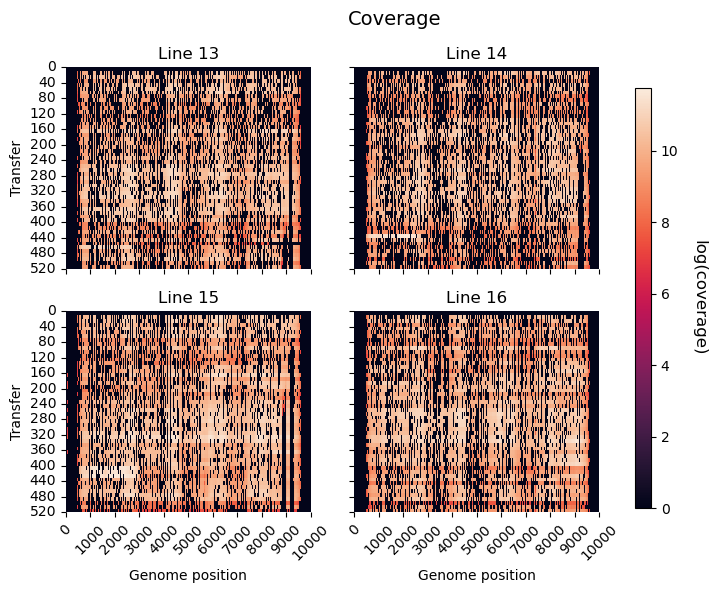

In [4]:
#Plot
fig, axes = plt.subplots(2,2,figsize=(8,6),sharex=True,sharey=True)
axes = axes.flatten()

for i, ax in enumerate(axes):
    im = sns.heatmap(coverage[i,:,:].T, ax=ax, cbar=False, vmin=coverage.min(), vmax=coverage.max())
    ax.set_title(f'Line {13+i}')
    ax.set_xticks(ticks=np.linspace(0,10000,11),labels=np.linspace(0,10000,11).astype(int),rotation=45)
    ax.set_yticks(ticks=np.linspace(0,52,14),labels=(np.linspace(0,52,14)*10).astype(int))
    if i>1:
        ax.set_xlabel('Genome position')
    if i==0 or i==2:
        ax.set_ylabel('Transfer')

cbar_ax = fig.add_axes([0.8, 0.15, 0.02, 0.7])
mappable = axes[-1].collections[0]
cbar = fig.colorbar(mappable, cax=cbar_ax)
cbar.set_label('log(coverage)', rotation=270, labelpad=20, fontsize=12)
plt.suptitle('Coverage',fontsize=14)
plt.tight_layout(rect=[0, 0, 0.8, 1])
plt.savefig(fig_path + "/coverage.pdf")
plt.show()

## Number mutations per genome

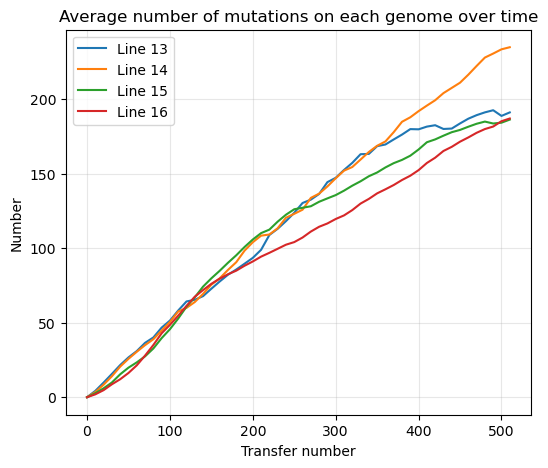

In [ ]:
#Calculate number of mutations
data = pd.read_pickle(out_path + "/mutation_time_series.pkl")
data = data[data['details'] != 'consensus']

mean_no_muts = np.zeros((4,52))
for i in range(4):
    data_line = data.loc[data['line'] == i+13]
    mean_no_muts[i,:] = data_line[np.arange(0,511,10)].sum(axis=0)

#Plot
fig, ax = plt.subplots(1,1,figsize=(6,5))

for i in range(4):
    ax.plot(np.arange(0,511,10),mean_no_muts[i,:],label=f'Line {i+13}')
ax.set_xlabel('Transfer number')
ax.set_ylabel("Number")
ax.set_title('Average number of mutations on each genome over time')
ax.grid(alpha=0.3)
ax.legend()
plt.savefig(fig_path + "/mutations_per_genome.pdf")
plt.show()

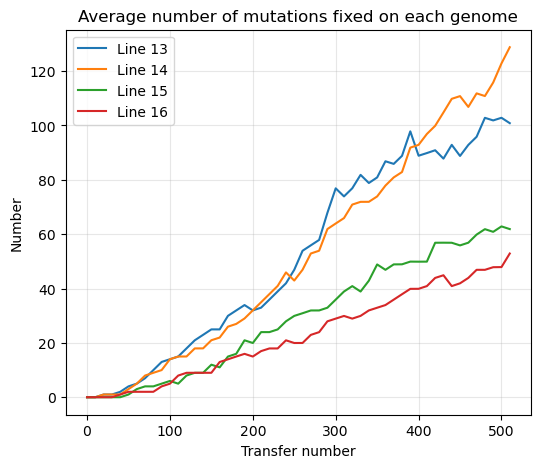

In [ ]:
#Calculate number of fixations
data = pd.read_pickle(out_path + "/mutation_time_series.pkl")
data = data[data['details'] != 'consensus']

mean_no_muts = np.zeros((4,52))
for i in range(4):
    data_line = data.loc[data['line'] == i+13]
    mean_no_muts[i,:] = np.where(data_line[np.arange(0,511,10)]>0.99,data_line[np.arange(0,511,10)],0).sum(axis=0)

#Plot
fig, ax = plt.subplots(1,1,figsize=(6,5))

for i in range(4):
    ax.plot(np.arange(0,511,10),mean_no_muts[i,:],label=f'Line {i+13}')
ax.set_xlabel('Transfer number')
ax.set_ylabel("Number")
ax.set_title('Average number of mutations fixed on each genome')
ax.grid(alpha=0.3)
ax.legend()
plt.savefig(fig_path + "/mutations_fixed_per_genome.pdf")
plt.show()

## Mutation positions

In [8]:
#Load mutation data
data = pd.read_pickle(out_path + "/mutation_data.pkl")
data['line'] = data['line'].astype(int)
data = data[data['line']<17]

#Get average frequencies and most frequent mutation
data_pos = (data.groupby(by=['pos','new','line','type']).sum()['fraction']/51).reset_index()
frequencies = data_pos.groupby(by=['pos','line']).sum()['fraction'].reset_index()
idx = data_pos.groupby(by=['pos','line'])['fraction'].idxmax()
most_frequent_mut = data_pos.loc[idx, ['pos','line', 'type', 'new']]

#Add colour column
cmap = plt.colormaps['Accent']
colors = list(cmap(np.linspace(0, 0.7, 6)))
color_map = {'substitution': colors[0],
             'insertion': colors[4],
             'deletion': colors[5]}

most_frequent_mut['colour'] = most_frequent_mut['type'].map(color_map)

#Merge frequencies and colors
data_hist = pd.merge(frequencies,most_frequent_mut, on=['pos','line'], how='inner')

#Get max genome position
pos_max = data_hist['pos'].max()

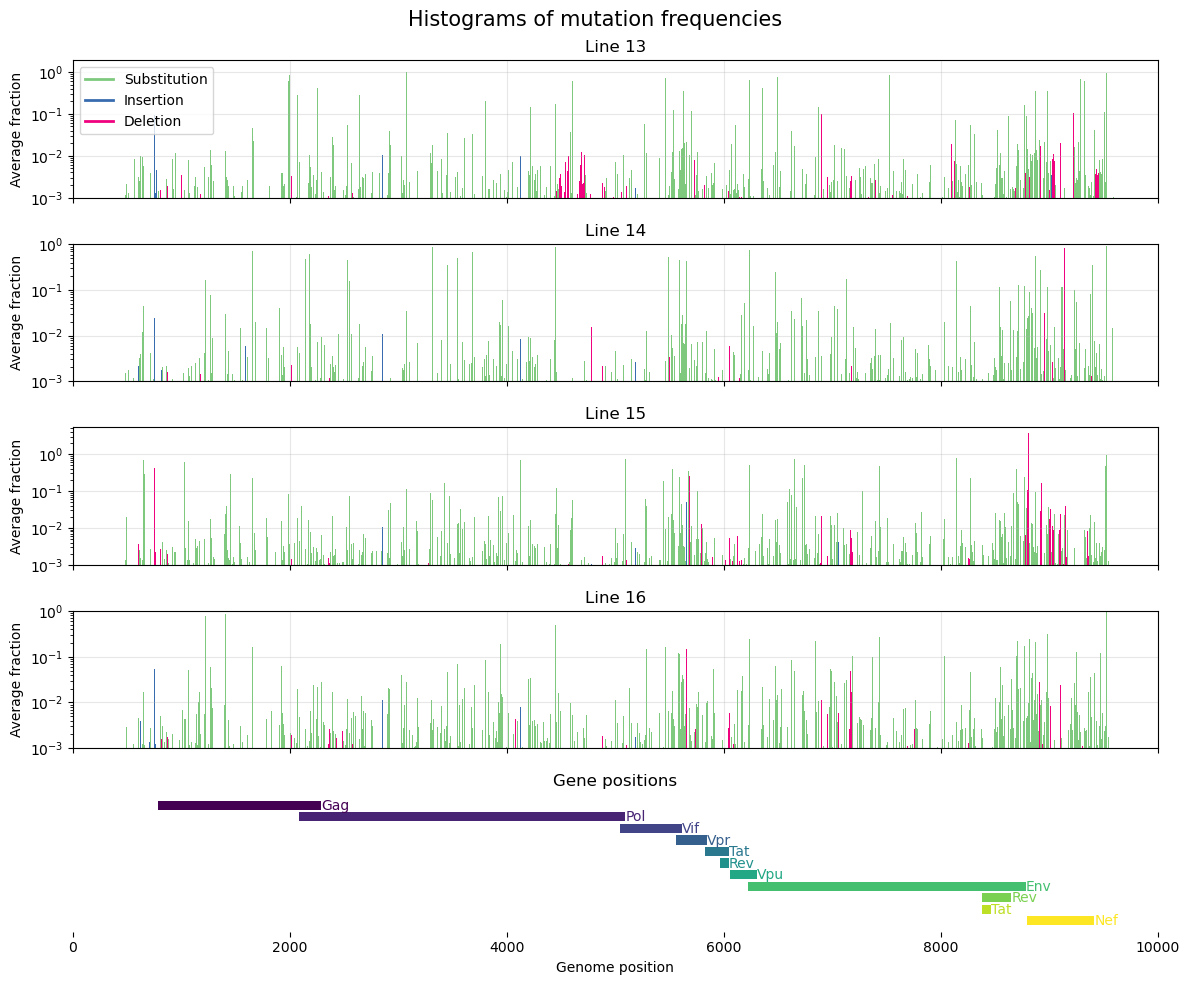

In [9]:
#Plot
fig, axes = plt.subplots(5,1,figsize=(12, 10),sharex=True)

#Plot gene positions
gene_data = pd.read_csv(data_path + '/genes.csv')
gene_colors = [plt.cm.viridis(j) for j in np.linspace(0, 1, len(gene_data))]

for i, row in gene_data.iterrows():    
    width = row['end'] - row['start']
    axes[4].broken_barh([(row['start'], width)], (-i-0.4, 0.8), facecolors=gene_colors[i])
    axes[4].text(row['end'],-i-0.4,row['genename'],c=gene_colors[i])

axes[4].set_xlabel("Genome position")
for spine in axes[4].spines.values():
    spine.set_visible(False)

axes[4].yaxis.set_ticks([])
axes[4].set_title("Gene positions")


#Plot histograms
for i in range(4):
    #Get data in correct form
    df = data_hist[data_hist['line']==i+13][['pos','fraction','colour']].set_index('pos')
    df_extended = df.reindex(np.arange(1, pos_max))
    df_extended = df_extended.fillna(value = {'fraction': 0, 'colour': 'white'})
    df_extended = df_extended.reset_index().rename(columns={'index': 'pos'})

    #Plot bars
    axes[i].bar(df_extended['pos'], df_extended['fraction'], width=1.0, color=df_extended['colour'], edgecolor='none')

    #Format
    axes[i].set_title(f'Line {i+13}')
    axes[i].set_ylabel('Average fraction')
    axes[i].grid(alpha=0.3)
    axes[i].set_xlim(0,10000)
    axes[i].set_ylim(bottom=0.001)
    axes[i].set_yscale('log')

#Legend
custom_lines = [
    Line2D([0], [0], color=colors[0], lw=2),
    Line2D([0], [0], color=colors[4], lw=2),
    Line2D([0], [0], color=colors[5], lw=2)
]


custom_labels = ['Substitution', 'Insertion', 'Deletion']
axes[0].legend(custom_lines, custom_labels, loc='upper left')

plt.suptitle(f"Histograms of mutation frequencies",fontsize=15)
plt.tight_layout()
plt.savefig(fig_path + "/mutations_positions.pdf")
plt.show()

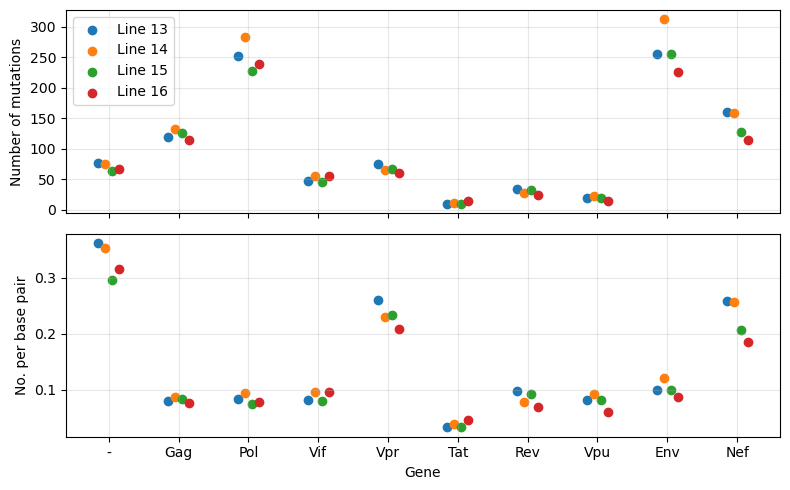

In [44]:
#Mutations in each gene
data = pd.read_pickle(out_path + f'/mutation_time_series.pkl')
data = data[data['details']!='consensus']

#Get mutation counts
counts = np.zeros((4,len(data['gene'].unique())))
for j,gene in enumerate(data['gene'].unique()):
    for i,line in enumerate([13,14,15,16]):
        data_line = data[data['line']==line]
        counts[i,j] = len(data_line[data_line['gene']==gene])

#Get gene lengths
lengths = []
for gene in data['gene'].unique():
    length_data = gene_data[gene_data['genename']==gene]
    lengths.append((length_data['end'] - length_data['start']).values.sum())
lengths[0] = 9665 - np.sum(lengths) #non-coding regions

#Plot
fig, (ax1,ax2) = plt.subplots(2,1,figsize=(8,5),sharex=True)

for i,line in enumerate([13,14,15,16]):
    ax1.scatter(0.1*i + np.arange(len(data['gene'].unique())),counts[i],label=f'Line {line}')
    ax2.scatter(0.1*i + np.arange(len(data['gene'].unique())),np.array(counts[i])/np.array(lengths))

ax1.legend()
ax2.set_xticks(ticks=0.15+np.arange(len(data['gene'].unique())),labels=data['gene'].unique())
ax2.set_xlabel('Gene')
ax1.set_ylabel('Number of mutations')
ax2.set_ylabel('No. per base pair')
for ax in [ax1,ax2]:
    ax.grid(alpha=0.3)


plt.tight_layout()
plt.savefig(fig_path + "/mutations_gene_counts.pdf")
plt.show()

Most mutations per bp seen in non-coding regions, followed by the accessory genes Vpr and Nef.

Lowest seen in the regulatory tat gene, responsible for RNA synthesis.

